# Assignment: Video Quality Inference

To this point in the class, you have learned various techniques for leading and analyzing packet captures of various types, generating features from those packet captures, and training and evaluating models using those features.

In this assignment, you will put all of this together, using a network traffic trace to train a model to automatically infer video quality of experience from a labeled traffic trace.

## Getting the data

Everything you need is in the `data/` folder next to this notebook (originally from the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), under `video-qoe/`). The files are:

| File | Used in | Size |
|---|---|---|
| `data/netflix.pcap` | Part 1 | 22 MB |
| `data/netflix_dataset.pkl.xz` *or* `data/video_dataset.pkl.xz` | Part 2 | 22 MB / 61 MB compressed |
| `data/netflix_session.pkl` | Part 3 | 130 KB |

## Part 1: Warmup

The first part of this assignment builds directly on the hands-on activities but extends them slightly.

### Extract Features from the Network Traffic

Load the `data/netflix.pcap` file, which is a packet trace that includes network traffic.



In [123]:
from netml.pparser.parser import PCAP
import pandas as pd
netflix_pcap = PCAP('data/netflix.pcap', flow_ptks_thres=2, verbose=10)
netflix_pcap.pcap2pandas()
netflix_pcap_df = netflix_pcap.df
netflix_pcap_df.head()

netflix_pcap = PCAP('data/netflix.pcap', flow_ptks_thres=2, verbose=10)
netflix_pcap.pcap2flows(interval=10)

pcap_file: data/netflix.pcap
ith_packets: 0
ith_packets: 10000
ith_packets: 20000
ith_packets: 30000
ith_packets: 40000
ith_packets: 50000
ith_packets: 60000
ith_packets: 70000
ith_packets: 80000
ith_packets: 90000
ith_packets: 100000
ith_packets: 110000
ith_packets: 120000
ith_packets: 130000
ith_packets: 140000
len(flows): 275
total number of flows: 275. Num of flows < 2 pkts: 91, and >=2 pkts: 184 without timeout splitting.
kept flows: 184. Each of them has at least 2 pkts after timeout splitting.
0th_flow: len(pkts): 12
After splitting flows, the number of subflows: 247 and each of them has at least 2 packets.


### Identifying the Service Type

Use the DNS traffic to filter the packet trace for Netflix traffic.

In [124]:
netflix_pcap.q_interval = 0.9 # Was getting an error realted to q_interval. Asked claude for help in order to debug
netflix_pcap.flow2features('STATS', fft=False, header=False)

dns_traffic = netflix_pcap_df[netflix_pcap_df['is_dns']]
dns_traffic = dns_traffic[dns_traffic['dns_resp'].notna()].copy()

dns_traffic['dns_query'] = dns_traffic['dns_query'].str[0]
dns_traffic['dns_resp'] = dns_traffic['dns_resp'].str[0]

# Now filtering for netflix in order to get the ips for netflix
dns_traffic = dns_traffic[dns_traffic['dns_query'].str.contains('netflix|nflx', case=False, na=False)]
display(dns_traffic[['dns_query', 'dns_resp']])

#Print the ips
netflix_ips = set(dns_traffic['dns_resp'])
print(len(netflix_ips), 'Netflix IPs:', netflix_ips)

True


,dns_query,dns_resp
101,ipv4-c001-cdg001-ix.1.oca.nflxvideo.net.,198.38.120.130
102,www.eu-west-1.prodaa.netflix.com.,52.19.39.146
103,customerevents.eu-west-1.prodaa.netflix.com.,52.210.19.176
104,ipv4-c024-cdg001-ix.1.oca.nflxvideo.net.,198.38.120.153
219,occ-0-56-55.1.nflxso.net.,198.38.120.137
228,ipv4-c072-cdg001-ix.1.oca.nflxvideo.net.,198.38.120.167
1019,push.prod.eu-west-1.prodaa.netflix.com.,34.252.77.54
1566,ipv4-c005-cdg001-ix.1.oca.nflxvideo.net.,198.38.120.134
1598,ipv4-c069-cdg001-ix.1.oca.nflxvideo.net.,198.38.120.164
1600,ipv4-c071-cdg001-ix.1.oca.nflxvideo.net.,198.38.120.166


15 Netflix IPs: {'52.48.148.78', '34.252.77.54', '52.48.8.150', '198.38.120.130', '198.38.120.134', '52.210.19.176', '52.19.39.146', '198.38.120.164', '198.38.120.166', '52.210.133.255', '198.38.120.153', '52.208.128.101', '198.38.120.167', '198.38.120.137', '198.38.120.162'}


### Generate Statistics

Generate statistics and features for the Netflix traffic flows. Use the `netml` library or any other technique that you choose to generate a set of features that you think would be good features for your model. 

In [125]:
# Now we will generate statistics based on the ips of the netflix stuff from aboce. 
cols = ['duration','pkts_rate','bytes_rate','mean','std','q1','median','q3','min','max','num_pkts','num_bytes']
features = ['duration', 'pkts_rate', 'bytes_rate', 'mean', 'std', 'num_pkts', 'num_bytes']
stats = pd.DataFrame(netflix_pcap.features, columns=cols)
stats['src'] = [f[0] for f in netflix_pcap.fids]
stats['dst'] = [f[1] for f in netflix_pcap.fids]

stats = stats[stats['src'].isin(netflix_ips) | stats['dst'].isin(netflix_ips)]
stats.reset_index()

netflix_features = stats[['src', 'dst'] + features]
netflix_features.head()

,src,dst,duration,pkts_rate,bytes_rate,mean,std,num_pkts,num_bytes
14,192.168.43.72,198.38.120.130,14.440177,0.831015,73.683308,88.666667,48.140997,12.0,1064.0
15,192.168.43.72,198.38.120.130,14.442865,0.761622,69.099863,90.727273,49.772374,11.0,998.0
16,192.168.43.72,198.38.120.130,14.437420,0.831173,73.697377,88.666667,48.140997,12.0,1064.0
17,192.168.43.72,52.19.39.146,23.744675,5.348568,535.993861,100.212598,57.904840,127.0,12727.0
18,192.168.43.72,52.19.39.146,5.314481,8.655596,1504.192031,173.782609,53.158055,46.0,7994.0


**Write a brief justification for the features that you have chosen.**

**Feature justification**

| Feature | Justification |
|---|---|
| `bytes_rate` | Bytres per second is probably the most important feature to understand video quality. Higher byte reate means larger video and high resolution vidoes. |
| `pkts_rate` | Shows how busy the flow is, and can show if the video is actively downloading if high byte and packet rate or control flow is high pkt rate and low byte.  |
| `mean` (packet size) | Video traffic mixes full-size data packets (~1500 B) with small ACKs. Need mean to see how much video is mixed in. |
| `std` (packet size) | A high std means a mix of large video packets and small control packets, which signals bursty segment downloads rather than steady traffic. |
| `duration` |  Within a 10 s window it shows whether the flow downloaded continuously or only in a short burst. |
| `num_pkts` | The total packet count in the window. Unlike `pkts_rate`, it isn't divided by duration, so it captures the total amount of activity even when a flow is only active for part of the window. |
| `num_bytes` | The total bytes in the window. It approximates how much video was downloaded in each 10 s interval. |

### Inferring Segment downloads

In addition to the features that you could generate using the `netml` library or similar, add to your feature vector a "segment downloads rate" feature, which indicates the number of video segments downloaded for a given time window.

Note: If you are using the `netml` library, generating features with `SAMP` style options may be useful, as this option gives you time windows, and you can then simply add the segment download rate to that existing dataframe.

In [126]:
# I think the video servers are like nflxvideo.net or something.
video_ips = set(dns_traffic.loc[dns_traffic['dns_query'].str.contains('nflxvideo'), 'dns_resp'])

upstream = netflix_pcap_df[netflix_pcap_df['ip_dst'].isin(video_ips)].copy()

display(upstream['length'].value_counts().sort_index())

# To find segments, ignore all teh normal acks, the stuff bascially below 100 and like find the ones with real headers likely
requests = upstream[upstream['length'] > 100].copy()
print(len(requests), 'segment requests') 

# 
requests['window'] = ((requests['time'].astype(float) - float(netflix_pcap_df['time'].min())) // 10)
segments_per_window = requests.groupby('window').size().rename('segments')
segments_per_window.head(10)

length
54       381
62         8
66     45291
78      3827
86      1088
94       703
105        2
117       15
192       17
200      242
Name: count, dtype: int64

276 segment requests


window
0.0     26
2.0     14
3.0      1
6.0     57
7.0     21
8.0      7
9.0      5
10.0     2
11.0     3
15.0    25
Name: segments, dtype: int64

## Part 2: Video Quality Inference

You will now load the complete video dataset from a previous study to train and test models based on these features to automatically infer the quality of a streaming video flow.

For this part of the assignment, you will need two pickle files, both in the `data/` folder:

- `data/netflix_session.pkl` (used in Part 3)
- `data/video_dataset.pkl.xz`

The dataset is stored xz-compressed (61 MB compressed, about 265 MB uncompressed). You do not need to decompress it first: `pd.read_pickle` reads `.pkl.xz` files directly, e.g. `pd.read_pickle('data/video_dataset.pkl.xz')`. (The uncompressed `.pkl` is git-ignored so it never gets committed.)

A smaller Netflix-only dataset (`data/netflix_dataset.pkl.xz`, 52,279 samples with 251 features) is available in the same folder and may be used instead of the multi-service `video_dataset.pkl.xz` (204,713 samples with 170 features).


### Load the File

Load the video dataset pickle file.

In [127]:
df = pd.read_pickle('data/netflix_dataset.pkl.xz')

# Hold out the Part 3 session so the model never sees it during training
session = pd.read_pickle('data/netflix_session.pkl')
held_out_id = session['session_id'].iloc[0]
print('rows from held-out session:', (df['session_id'] == held_out_id).sum())
df = df[df['session_id'] != held_out_id]

print(df.shape)
df.head()

rows from held-out session: 61
(52218, 251)


,10_EWMA_chunksizes,10_avg_chunksize,10_chunksizes_50,10_chunksizes_50R,10_chunksizes_75,10_chunksizes_75R,10_chunksizes_85,10_chunksizes_85R,10_chunksizes_90,10_chunksizes_90R,...,userTwoRetransmit,userUrgFlags,userXRetransmit,userZeroRetransmit,service,startup3.3,startup6.6,startup5,startup10,startup_mc
208,"[[4380.0], [4380.0], [19682.095238095237], [23...",148947.1,43473.0,43473.0,185098.0,185098.0,361832.3,361832.3,461040.2,461040.2,...,0.0,0,0.108730,0.557937,netflix,False,False,False,False,12.0
209,"[[179260.0], [130204.0], [49666.09523809524], ...",91984.2,101882.0,101882.0,122323.0,122323.0,159843.4,159843.4,181011.8,181011.8,...,0.0,0,0.116865,0.549802,netflix,False,False,False,False,12.0
210,"[[317962.0], [83192.4], [170850.7619047619], [...",147725.0,111373.0,111373.0,224157.0,224157.0,286280.0,286280.0,325845.8,325845.8,...,0.0,0,0.126852,0.539815,netflix,False,False,False,False,12.0
211,"[[396800.0], [98961.6], [246910.09523809524], ...",246420.6,297522.0,297522.0,330737.5,330737.5,361030.7,361030.7,378404.0,378404.0,...,0.0,0,0.186111,0.480556,netflix,False,False,False,False,12.0
212,"[[325264.0], [331102.4], [365584.38095238095],...",336681.0,354461.0,354461.0,399719.5,399719.5,409866.3,409866.3,414060.0,414060.0,...,0.0,0,0.194444,0.472222,netflix,False,False,False,False,12.0


### Clean the File

1. The dataset contains video resolutions that are not valid. Remove entries in the dataset that do not contain a valid video resolution. Valid resolutions are 240, 360, 480, 720, 1080.

In [128]:
# Check resolutons
display(df['resolution'].value_counts().sort_index())
# Remove the zero
df = df[df['resolution'] != 0]
groups = df['session_id']
display(df['resolution'].value_counts().sort_index())

resolution
0.0        2529
240.0      1694
360.0      4470
480.0     29475
720.0      9430
1080.0     4620
Name: count, dtype: int64

resolution
240.0      1694
360.0      4470
480.0     29475
720.0      9430
1080.0     4620
Name: count, dtype: int64

2. The file also contains columns that are unnecessary (in fact, unhelpful!) for performing predictions. Identify those columns, and remove them.

In [129]:
# Can't basically use any like unvalid resolutiosn adn remove columsn not related to like ints or features we care about
df.dtypes.value_counts()
cols_to_remove = df.select_dtypes('object').columns

# Remove text columns
df = df.drop(columns=cols_to_remove)

# Droppign columsn of not much value
extra_stats = [
    '10_chunksizes_50R', '10_chunksizes_75R', '10_chunksizes_85', '10_chunksizes_85R', '10_chunksizes_90R',
    '10_max_chunksize', '10_min_chunksize', '10_std_chunksize',
    'allprev_chunksizes_50R', 'allprev_chunksizes_75R', 'allprev_chunksizes_85', 'allprev_chunksizes_85R', 'allprev_chunksizes_90R',
    'allprev_max_chunksize', 'allprev_min_chunksize', 'allprev_std_chunksize',
    'down_chunk_iat_50R', 'down_chunk_iat_75R', 'down_chunk_iat_85', 'down_chunk_iat_85R', 'down_chunk_iat_90R',
    'down_chunk_iat_max', 'down_chunk_iat_min', 'down_chunk_iat_std',
    'up_chunk_iat_50R', 'up_chunk_iat_75R', 'up_chunk_iat_85', 'up_chunk_iat_85R', 'up_chunk_iat_90R',
    'up_chunk_iat_max', 'up_chunk_iat_min', 'up_chunk_iat_std',
    'all_prev_down_chunk_iat_50R', 'all_prev_down_chunk_iat_75R', 'all_prev_down_chunk_iat_85', 'all_prev_down_chunk_iat_85R', 'all_prev_down_chunk_iat_90R',
    'all_prev_down_chunk_iat_max', 'all_prev_down_chunk_iat_min', 'all_prev_down_chunk_iat_std',
    'all_prev_up_chunk_iat_50R', 'all_prev_up_chunk_iat_75R', 'all_prev_up_chunk_iat_85', 'all_prev_up_chunk_iat_85R', 'all_prev_up_chunk_iat_90R',
    'all_prev_up_chunk_iat_max', 'all_prev_up_chunk_iat_min', 'all_prev_up_chunk_iat_std', 'access_50_perc', 'access_75_perc', 'access_avg', 'access_max', 'access_min',
    'access_stddev', 'access_var', 'ads', 'userThroughput', 'userTwoRetransmit', 'userUrgFlags'
]
df = df.drop(columns=extra_stats)

hurtful_columns = ['bitrate', 'bitrate_change', 'c_bitrate_switches', 'n_bitrate_switches', 'previous_bitrate', 'serverBitrateChange'] 

df.drop(columns=hurtful_columns)

,10_avg_chunksize,10_chunksizes_50,10_chunksizes_75,10_chunksizes_90,absolute_timestamp,all_prev_down_chunk_iat_50,all_prev_down_chunk_iat_75,all_prev_down_chunk_iat_90,all_prev_down_chunk_iat_avg,all_prev_up_chunk_iat_50,...,userStdRwnd,userStrBytesInFlight,userSynFlags,userXRetransmit,userZeroRetransmit,startup3.3,startup6.6,startup5,startup10,startup_mc
208,148947.1,43473.0,185098.0,461040.2,1.548881e+09,161.5,602.50,3144.3,808.400000,38.0,...,985.136457,0,4,0.108730,0.557937,False,False,False,False,12.0
209,91984.2,101882.0,122323.0,181011.8,1.548881e+09,361.0,614.00,938.1,588.666667,114.5,...,310.123152,0,1,0.116865,0.549802,False,False,False,False,12.0
210,147725.0,111373.0,224157.0,325845.8,1.548881e+09,337.0,620.00,1517.6,574.836735,61.0,...,149.669427,0,0,0.126852,0.539815,False,False,False,False,12.0
211,246420.6,297522.0,330737.5,378404.0,1.548881e+09,399.0,652.00,1773.6,658.894737,186.0,...,14006.713648,0,1,0.186111,0.480556,False,False,False,False,12.0
212,336681.0,354461.0,399719.5,414060.0,1.548881e+09,414.0,782.25,1859.7,744.483871,216.5,...,13261.305817,0,0,0.194444,0.472222,False,False,False,False,12.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200633,498288.4,562720.0,587584.0,616109.6,1.514565e+09,3409.5,3937.75,4073.1,2147.796154,4001.5,...,13.435795,0,0,0.027778,0.055556,False,True,True,True,4.0
200634,495682.8,545831.0,587584.0,623059.4,1.514565e+09,3521.0,3941.50,4073.0,2154.608365,4002.0,...,585.225972,0,0,0.062500,0.104167,False,True,True,True,4.0
200635,558961.0,555966.0,671688.5,778571.2,1.514565e+09,3574.5,3943.75,4079.0,2176.000000,4002.0,...,16.024488,0,0,0.027778,0.055556,False,True,True,True,4.0
200636,599166.8,584205.0,744688.5,937127.8,1.514565e+09,3563.0,3944.00,4076.0,2181.249071,4002.0,...,525.627151,0,0,0.062500,0.104167,False,True,True,True,4.0


**Briefly explain why you removed those columns.**

For columns in `cols_to_remove`, I removed them because they were not neccessary since they were non-number values. 

For columns in `extra_columns`, they were features I felt were already represented by columns like 10_chunksize_50 vs 10_chunksize_50R or they were fully zero or false. They proviode zero value to the model so may aswell drop them.

For columns in `hurtful_columns`, they were columns I felt actively held the answer to the question we are trying to infer, which is what was the strength of the streaming, which can be measured by bitrate. However, as someone analyzing encrypted network traffic, you dont have access to the bitrate. You must therefore look for soemthign else to understand resolution.

### Prepare Your Data

Prepare your data matrix, determine your features and labels, and perform a train-test split on your data.

In [130]:
y = df['resolution']
X = df.drop(columns=['resolution']) 

X = X.fillna(0)
print(X.shape, y.shape)

(49689, 184) (49689,)


### Train and Tune Your Model

1. Select a model of your choice.
2. Train the model using your training data.

In [131]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(len(X_train), 'train rows |', len(X_test), 'test rows')

39639 train rows | 10050 test rows


test accuracy: 0.8851741293532338
              precision    recall  f1-score   support

       240.0       0.67      0.47      0.55       271
       360.0       0.90      0.71      0.79       806
       480.0       0.88      0.97      0.93      6132
       720.0       0.90      0.73      0.81      2050
      1080.0       0.94      0.91      0.92       791

    accuracy                           0.89     10050
   macro avg       0.86      0.76      0.80     10050
weighted avg       0.88      0.89      0.88     10050

AUC:  0.9780807972173614


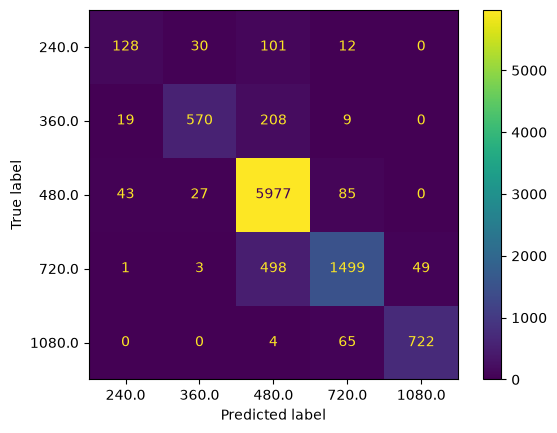

In [132]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, accuracy_score, classification_report

model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('test accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

probability = model.predict_proba(X_test)
print('AUC: ', roc_auc_score(y_test, probability, multi_class='ovr', labels=model.classes_))

### Evaluate Your Model

Evaluate your model accuracy according to the following metrics:

1. Accuracy
2. F1 Score
3. Confusion Matrix
4. ROC/AUC

## Part 3: Predict the Ongoing Resolution of a Real Netflix Session

Now that you have your model, it's time to put it in practice!

Use a preprocessed Netflix video session to infer **and plot** the resolution at 10-second time intervals. The session is `netflix_session.pkl` (in the `data/` folder; 59 ten-second windows with the same 251 features as `netflix_dataset.pkl`, plus the true `resolution` so you can check yourself):

```python
session = pd.read_pickle('data/netflix_session.pkl')
```

exact match: 0.23728813559322035


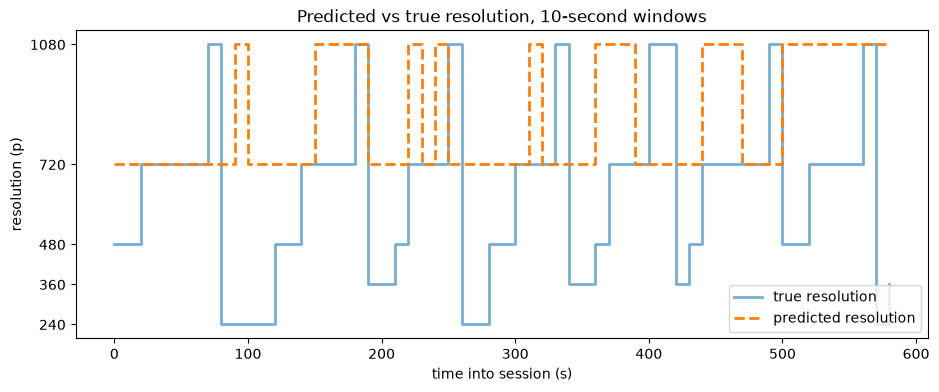

In [133]:
import numpy as np
import matplotlib.pyplot as plt

session = pd.read_pickle('data/netflix_session.pkl')

# same columns as training, in the same order (this drops everything you removed in Part 2 automatically)
X_session = session[X_train.columns].astype(float).fillna(0)
y_true = session['resolution'].astype(int)

# predict one resolution per 10-second window
y_pred = model.predict(X_session)
t = np.arange(len(session)) * 10      # 0, 10, 20, ... seconds

print('exact match:', (y_pred == y_true.values).mean())

plt.figure(figsize=(11, 4))
plt.step(t, y_true, where='post', label='true resolution', lw=2, alpha=0.6)
plt.step(t, y_pred, where='post', label='predicted resolution', lw=2, ls='--')
plt.yticks([240, 360, 480, 720, 1080])
plt.xlabel('time into session (s)')
plt.ylabel('resolution (p)')
plt.title('Predicted vs true resolution, 10-second windows')
plt.legend()
plt.show()